# Занятие 5. Формирование датасета изображений
## Объекты, классы, разметка и train/test

**Часть 1** — демонстрация преподавателя.  
**Часть 2** — самостоятельные операции по 1–2 строки в `# YOUR CODE HERE`.

## Часть 1. Демонстрация преподавателя

Цель — увидеть датасет как согласованный набор **изображений + правильных меток**, а не просто как массив картинок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (8, 4)
digits = load_digits()
images = digits.images
labels = digits.target
print('images:', images.shape)
print('labels:', labels.shape)

images: (1797, 8, 8)
labels: (1797,)


### 1. Один индекс связывает изображение и label
`images[i]` и `labels[i]` относятся к одному объекту.

label: 5


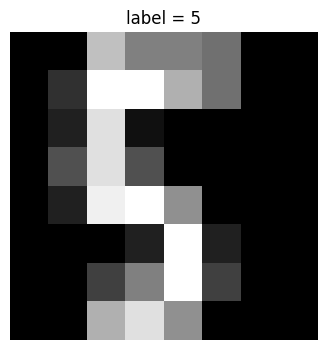

In [2]:
i = 25
print('label:', labels[i])
plt.imshow(images[i], cmap='gray', vmin=0, vmax=16)
plt.title(f'label = {labels[i]}')
plt.axis('off'); plt.show()

### 2. Смотрим случайные пары, а не только числа
Визуальная проверка помогает заметить ошибку разметки.

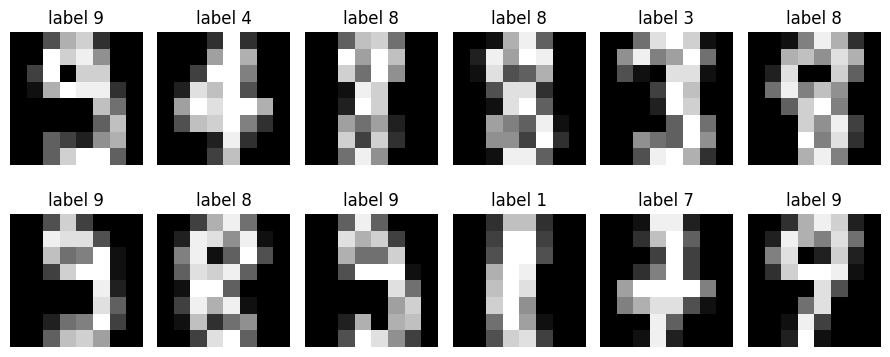

In [3]:
rng = np.random.default_rng(42)
idx = rng.choice(len(images), size=12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(9, 4))
for ax, j in zip(axes.ravel(), idx):
    ax.imshow(images[j], cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'label {labels[j]}')
    ax.axis('off')
plt.tight_layout(); plt.show()

### 3. Классы и их количество
До обучения проверяем, какие классы есть и сколько объектов относится к каждому.

classes: [0 1 2 3 4 5 6 7 8 9]
counts : [178 182 177 183 181 182 181 179 174 180]


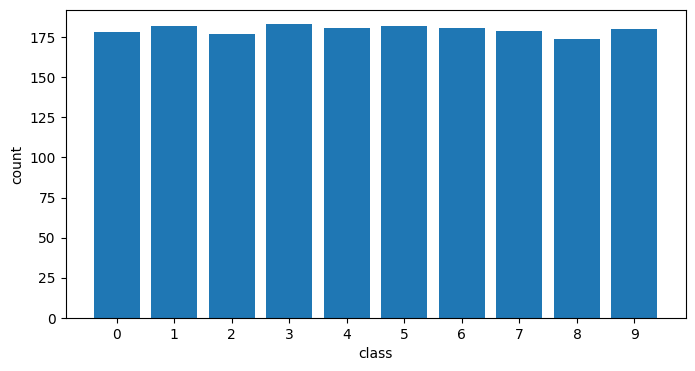

In [4]:
classes, counts = np.unique(labels, return_counts=True)
print('classes:', classes)
print('counts :', counts)
plt.bar(classes, counts)
plt.xticks(classes); plt.xlabel('class'); plt.ylabel('count'); plt.show()

### 4. Подвыборка по условию
Булева маска позволяет собрать новый датасет, не разрывая связь X и y.

In [5]:
mask_17 = (labels == 1) | (labels == 7)
images_17 = images[mask_17]
labels_17 = labels[mask_17]
print(images_17.shape, labels_17.shape, np.unique(labels_17, return_counts=True))

(361, 8, 8) (361,) (array([1, 7]), array([182, 179]))


### 5. Перемешивать нужно пары
Одна permutation применяется и к изображениям, и к labels.

In [6]:
perm = rng.permutation(len(images_17))
shuffled_images = images_17[perm]
shuffled_labels = labels_17[perm]
print('первые labels после shuffle:', shuffled_labels[:12])

первые labels после shuffle: [7 1 1 1 7 1 1 1 1 7 1 1]


### 6. Train/test со stratify
Разделяем X и y вместе и сохраняем примерно одинаковые доли классов.

In [7]:
X_train_img, X_test_img, y_train, y_test = train_test_split(
    images, labels, test_size=0.25, random_state=42, stratify=labels
)
print('train:', X_train_img.shape, y_train.shape)
print('test :', X_test_img.shape, y_test.shape)
print('train counts:', np.bincount(y_train))
print('test counts :', np.bincount(y_test))

train: (1347, 8, 8) (1347,)
test : (450, 8, 8) (450,)
train counts: [133 136 133 137 136 136 136 134 131 135]
test counts : [45 46 44 46 45 46 45 45 43 45]


### 7. Test пока оставляем изображениями
Обратите внимание: мы **не обязаны** уже сейчас вытягивать 8×8 в 64 признака. Представление изображения выберем на следующих занятиях.

In [8]:
print('Один train-объект:', X_train_img[0].shape)
print('Его label:', y_train[0])

Один train-объект: (8, 8)
Его label: 2


---
## Часть 2. Самостоятельные мини-задачи

Работаем с уже загруженными `images` и `labels`.

### Задание 1. Сколько объектов в датасете?
Запишите число изображений в `n_samples`.

In [9]:
# YOUR CODE HERE (1 строка)
# n_samples = ...

### Задание 2. Какого размера одно изображение?
Запишите `image_shape`.

In [10]:
# YOUR CODE HERE (1 строка)
# image_shape = ...

### Задание 3. Какие есть классы?
Создайте `classes_s` через `np.unique`.

In [11]:
# YOUR CODE HERE (1 строка)
# classes_s = ...

### Задание 4. Сколько примеров цифры 7?
Запишите число в `n_sevens`.

In [12]:
# YOUR CODE HERE (1 строка)
# n_sevens = ...

### Задание 5. Оставьте только 1 и 7
Создайте булеву маску `mask_s`.

In [13]:
# YOUR CODE HERE (1 строка)
# mask_s = ...

### Задание 6. Создайте поддатасет 1/7
Получите `X_17_s` и `y_17_s`.

In [14]:
# YOUR CODE HERE (2 строки)
# X_17_s = ...
# y_17_s = ...

### Задание 7. Посчитайте распределение классов
Создайте `class_counts_s` длины 10 через `np.bincount`.

In [15]:
# YOUR CODE HERE (1 строка)
# class_counts_s = ...

### Задание 8. Разделите датасет
25% в test, `random_state=1`, `stratify=labels`.

In [16]:
# YOUR CODE HERE (1–3 строки)
# Xtr_s, Xte_s, ytr_s, yte_s = ...

### Задание 9. Проверьте распределение в train
Создайте `train_counts_s`.

In [17]:
# YOUR CODE HERE (1 строка)
# train_counts_s = ...

### Мини-вопрос
Почему нельзя отдельно случайно перемешать `images` и отдельно `labels`? И зачем при небольшом датасете полезен `stratify`?